# 03 - Model Training, Optimization, Evaluation and Saving

**Task 03, Parts 2, 3 and 4.**

| Task sheet requirement | Where in this notebook |
|---|---|
| Part 2: train at least four models (Random Forest, SVM, Gradient Boosting, Decision Tree; XGBoost optional) | Sections 2-3 |
| Part 3: hyperparameter tuning, cross-validation, feature importance | Sections 3, 4 and 7 |
| Part 4: save the best model with Joblib **and** Pickle | Section 8 |

**Rules that keep the result honest**
- Models are compared and tuned using **cross-validation on the training set only**.
- The best model is chosen from those cross-validation scores **automatically in code**, before the test set is looked at.
- The test set is used **once**, for the final report.
- Every model uses the identical preprocessing pipeline from `src/modeling.py`, so the comparison is fair.

In [1]:
import json
import pickle
import platform
import subprocess
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

try:
    from xgboost import XGBRegressor
    HAVE_XGB = True
except ImportError:                      # XGBoost is optional in the task sheet
    HAVE_XGB = False

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.car_features import RAW_INPUT_COLUMNS, REQUIRED_INPUT_COLUMNS
from src.modeling import (CATEGORICAL_FEATURES, CV_SCORING, NUMERIC_FEATURES, RANDOM_STATE,
                          TARGET, build_pipeline, regression_metrics)

PROCESSED = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)

train = pd.read_csv(PROCESSED / "train.csv")
test = pd.read_csv(PROCESSED / "test.csv")
X_train, y_train = train[RAW_INPUT_COLUMNS], train[TARGET]
X_test, y_test = test[RAW_INPUT_COLUMNS], test[TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape, "| XGBoost available:", HAVE_XGB)
print("Features used by the model ->", "numeric:", NUMERIC_FEATURES, "| categorical:", CATEGORICAL_FEATURES)

Train: (5540, 11) | Test: (1386, 11) | XGBoost available: True
Features used by the model -> numeric: ['car_age', 'log_km_driven', 'mileage', 'engine', 'max_power'] | categorical: ['brand', 'fuel', 'transmission', 'owner']


## 1. How we measure success

The target is a price, so this is **regression**. Accuracy / precision / recall do not apply. We report:

| Metric | Meaning | Direction |
|---|---|---|
| **RMSLE** | error on the log-price scale, roughly a *typical percentage error*. Treats a 10% miss on a cheap car and on an expensive car alike. **This is our selection metric.** | lower is better |
| **R2** | share of price variation explained (1.0 = perfect) | higher is better |
| **MAE** | average absolute error in rupees | lower is better |
| **RMSE** | like MAE but punishes big misses more (dominated by expensive cars) | lower is better |
| **MedAPE %** | median absolute percentage error, easy to explain to a non-technical reader | lower is better |

*Why RMSLE for selection?* Prices range from about 30 thousand to 10 million. RMSE and MAE are dominated by a few expensive cars, while RMSLE measures relative error across the whole range.

## 2. Part 2: Train the models (default settings, 5-fold cross-validation)

First a **sanity baseline**: a model that always predicts the median price. Any real model must beat it clearly.
We also add a simple **Ridge regression** as a reference (not required by the task sheet) to see whether complex models earn their extra complexity.

In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base_models = {
    "Baseline (always median price)": DummyRegressor(strategy="median"),
    "Ridge regression (reference)":   Ridge(alpha=1.0),
    "Decision Tree":                  DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest":                  RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":              GradientBoostingRegressor(random_state=RANDOM_STATE),
    "SVR (Support Vector Machine)":   SVR(),
}
if HAVE_XGB:
    base_models["XGBoost (optional)"] = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist")

def summarize_cv(res):
    return {"RMSLE": -res["test_neg_rmsle"].mean(), "RMSLE_std": res["test_neg_rmsle"].std(),
            "R2": res["test_r2"].mean(), "MAE": -res["test_neg_mae"].mean(),
            "RMSE": -res["test_neg_rmse"].mean(), "fit_seconds": res["fit_time"].mean()}

baseline_cv = {}
for name, model in base_models.items():
    res = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=CV_SCORING)
    baseline_cv[name] = summarize_cv(res)
    print(f"done: {name:32s} RMSLE {baseline_cv[name]['RMSLE']:.4f}")

baseline_table = pd.DataFrame(baseline_cv).T.sort_values("RMSLE").round(4)
display(baseline_table)

done: Baseline (always median price)   RMSLE 0.7678


done: Ridge regression (reference)     RMSLE 0.2626


done: Decision Tree                    RMSLE 0.2990


done: Random Forest                    RMSLE 0.2300


done: Gradient Boosting                RMSLE 0.2342


done: SVR (Support Vector Machine)     RMSLE 0.2295


done: XGBoost (optional)               RMSLE 0.2284


,RMSLE,RMSLE_std,R2,MAE,RMSE,fit_seconds
XGBoost (optional),0.2284,0.0108,0.8742,79318.7625,182125.2656,0.3507
SVR (Support Vector Machine),0.2295,0.0122,0.8337,82505.8589,206642.4552,0.8577
Random Forest,0.2300,0.0104,0.8840,80463.6070,175723.2566,3.2726
Gradient Boosting,0.2342,0.0091,0.8688,87347.3114,187309.2664,0.7363
Ridge regression (reference),0.2626,0.0136,0.8655,97882.9919,191768.5253,0.0763
Decision Tree,0.2990,0.0108,0.7899,103835.0128,232547.5022,0.1344
Baseline (always median price),0.7678,0.0182,-0.0520,282423.2540,540849.7186,0.1411


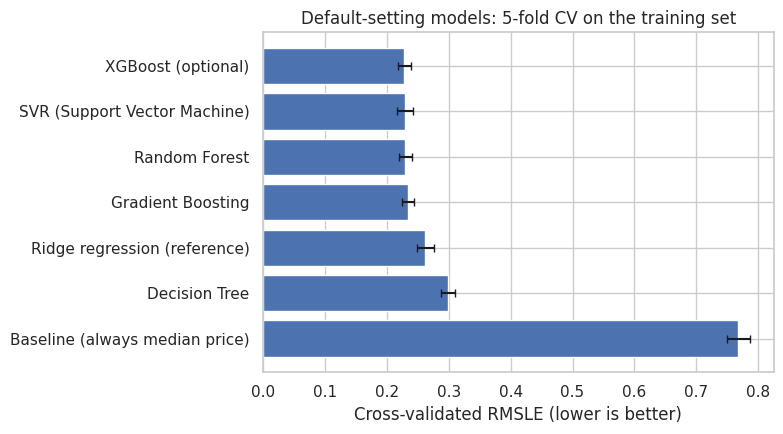

In [3]:
plot_df = baseline_table.sort_values("RMSLE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_df.index, plot_df["RMSLE"], xerr=plot_df["RMSLE_std"], color="#4C72B0", capsize=3)
ax.set_xlabel("Cross-validated RMSLE (lower is better)")
ax.set_title("Default-setting models: 5-fold CV on the training set")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_baseline_cv.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Part 3: Hyperparameter tuning

**Method:** `RandomizedSearchCV` tries 15 random combinations per model from the ranges below, scoring each with 5-fold cross-validation on the training set. We use random search (not a full grid) because it covers wide ranges in much less time, which matters on a laptop.

**Limitations to state honestly:** 15 combinations is a modest search, so a different search could find slightly better settings; small score differences between tuned models are within fold-to-fold noise.

In [4]:
P = "regressor__model__"       # prefix that reaches the model inside our pipeline
N_ITER = 15

search_spaces = {
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE), {
        P + "max_depth": [4, 6, 8, 10, 12, 15, None],
        P + "min_samples_leaf": [1, 2, 5, 10, 20],
        P + "min_samples_split": [2, 5, 10, 20],
    }),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        P + "n_estimators": [100, 200, 300],
        P + "max_depth": [None, 10, 15, 20],
        P + "min_samples_leaf": [1, 2, 4],
        P + "max_features": ["sqrt", 0.5, 1.0],
    }),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), {
        P + "n_estimators": [100, 200, 300, 400],
        P + "learning_rate": [0.03, 0.05, 0.1, 0.2],
        P + "max_depth": [2, 3, 4, 5],
        P + "subsample": [0.7, 0.85, 1.0],
        P + "min_samples_leaf": [1, 5, 10],
    }),
    "SVR (Support Vector Machine)": (SVR(), {
        P + "C": [1, 3, 10, 30, 100],
        P + "epsilon": [0.01, 0.05, 0.1, 0.2],
        P + "gamma": ["scale", 0.01, 0.03, 0.1],
    }),
}
if HAVE_XGB:
    search_spaces["XGBoost (optional)"] = (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist"), {
        P + "n_estimators": [200, 400, 600],
        P + "learning_rate": [0.03, 0.05, 0.1],
        P + "max_depth": [3, 4, 5, 6],
        P + "subsample": [0.7, 0.85, 1.0],
        P + "colsample_bytree": [0.6, 0.8, 1.0],
        P + "min_child_weight": [1, 3, 5],
    })

tuning_scoring = {"rmsle": "neg_root_mean_squared_log_error", "r2": "r2", "mae": "neg_mean_absolute_error"}
searches, tuned_cv, best_params = {}, {}, {}

for name, (model, space) in search_spaces.items():
    t0 = time.perf_counter()
    s = RandomizedSearchCV(build_pipeline(model), space, n_iter=N_ITER, cv=cv, scoring=tuning_scoring,
                           refit="rmsle", random_state=RANDOM_STATE, n_jobs=1)
    s.fit(X_train, y_train)
    i = s.best_index_
    searches[name] = s
    tuned_cv[name] = {"RMSLE": -s.cv_results_["mean_test_rmsle"][i], "RMSLE_std": s.cv_results_["std_test_rmsle"][i],
                      "R2": s.cv_results_["mean_test_r2"][i], "MAE": -s.cv_results_["mean_test_mae"][i]}
    best_params[name] = {k.replace(P, ""): (v.item() if hasattr(v, "item") else v) for k, v in s.best_params_.items()}
    print(f"{name:30s} tuned CV RMSLE {tuned_cv[name]['RMSLE']:.4f} | {time.perf_counter() - t0:.0f}s")

Decision Tree                  tuned CV RMSLE 0.2623 | 12s


Random Forest                  tuned CV RMSLE 0.2227 | 146s


Gradient Boosting              tuned CV RMSLE 0.2209 | 140s


SVR (Support Vector Machine)   tuned CV RMSLE 0.2299 | 259s


XGBoost (optional)             tuned CV RMSLE 0.2178 | 31s


In [5]:
tuned_table = pd.DataFrame(tuned_cv).T.sort_values("RMSLE").round(4)
print("Tuned models (5-fold CV on training set):")
display(tuned_table)

compare = pd.DataFrame({
    "CV RMSLE default": {k: baseline_cv[k]["RMSLE"] for k in tuned_cv},
    "CV RMSLE tuned":   {k: tuned_cv[k]["RMSLE"] for k in tuned_cv},
})
compare["improvement"] = compare["CV RMSLE default"] - compare["CV RMSLE tuned"]
print("Did tuning help? (positive improvement = lower error)")
display(compare.round(4).sort_values("CV RMSLE tuned"))

print("Best settings found:")
for k, v in best_params.items():
    print(f"  {k}: {v}")

Tuned models (5-fold CV on training set):


,RMSLE,RMSLE_std,R2,MAE
XGBoost (optional),0.2178,0.0113,0.8825,77569.7266
Gradient Boosting,0.2209,0.0108,0.8843,78690.7751
Random Forest,0.2227,0.0105,0.8769,80045.7194
SVR (Support Vector Machine),0.2299,0.0125,0.8338,82123.8479
Decision Tree,0.2623,0.0087,0.8375,94891.9537


Did tuning help? (positive improvement = lower error)


,CV RMSLE default,CV RMSLE tuned,improvement
XGBoost (optional),0.2284,0.2178,0.0106
Gradient Boosting,0.2342,0.2209,0.0133
Random Forest,0.2300,0.2227,0.0073
SVR (Support Vector Machine),0.2295,0.2299,-0.0004
Decision Tree,0.2990,0.2623,0.0367


Best settings found:
  Decision Tree: {'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': None}
  Random Forest: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20}
  Gradient Boosting: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 4, 'learning_rate': 0.1}
  SVR (Support Vector Machine): {'gamma': 'scale', 'epsilon': 0.05, 'C': 1}
  XGBoost (optional): {'subsample': 0.85, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


## 4. Choosing the best model

Rule (fixed in advance): **the model with the lowest tuned cross-validated RMSLE wins.** The code picks it; we do not choose by hand and we have not looked at the test set yet. We also check whether the runner-up is a statistical tie.

In [6]:
ranking = tuned_table.copy()
best_name = ranking.index[0]
runner_up = ranking.index[1]
gap = ranking.loc[runner_up, "RMSLE"] - ranking.loc[best_name, "RMSLE"]
noise = ranking.loc[best_name, "RMSLE_std"]

print(f"Selected model: {best_name}")
print(f"  CV RMSLE {ranking.loc[best_name, 'RMSLE']:.4f} (+/- {noise:.4f} across folds)")
print(f"Runner-up: {runner_up} (CV RMSLE {ranking.loc[runner_up, 'RMSLE']:.4f}); gap = {gap:.4f}")
print("Gap is smaller than the fold-to-fold noise -> practically a TIE" if gap < noise
      else "Gap is larger than the fold-to-fold noise -> a clear winner")

best_model = searches[best_name].best_estimator_      # already refit on the full training set

Selected model: XGBoost (optional)
  CV RMSLE 0.2178 (+/- 0.0113 across folds)
Runner-up: Gradient Boosting (CV RMSLE 0.2209); gap = 0.0031
Gap is smaller than the fold-to-fold noise -> practically a TIE


## 5. Final evaluation on the held-out test set (used once)

All tuned models are scored on the 20% of cars that no model has seen, so the report is transparent. **The selection above was made from cross-validation only.**

In [7]:
final_models = {"Baseline (always median price)": build_pipeline(DummyRegressor(strategy="median")).fit(X_train, y_train)}
final_models.update({k: s.best_estimator_ for k, s in searches.items()})

test_rows = {}
for name, model in final_models.items():
    test_rows[name] = regression_metrics(y_test, model.predict(X_test))
test_table = pd.DataFrame(test_rows).T.sort_values("RMSLE")
display(test_table.round(4))

test_table.round(4).to_csv(ROOT / "reports" / "test_set_results.csv")
pd.concat({"tuned_cv": tuned_table, "default_cv": baseline_table}, axis=1).round(4).to_csv(ROOT / "reports" / "cv_results.csv")
print("Selected model on test set:")
print({k: round(v, 4) for k, v in test_table.loc[best_name].items()})

,R2,MAE,RMSE,RMSLE,MedAPE_%
XGBoost (optional),0.9275,71361.4968,126069.0927,0.2153,12.3102
Gradient Boosting,0.9401,69992.0890,114649.3436,0.2164,12.6330
Random Forest,0.9225,72025.0491,130393.5133,0.2250,12.5571
SVR (Support Vector Machine),0.8544,76555.9533,178725.6216,0.2279,12.6667
Decision Tree,0.8987,84068.9793,149088.7799,0.2547,13.9246
Baseline (always median price),-0.0460,259546.7302,478963.2654,0.7488,42.8571


Selected model on test set:
{'R2': 0.9275, 'MAE': 71361.4968, 'RMSE': 126069.0927, 'RMSLE': 0.2153, 'MedAPE_%': 12.3102}


## 6. Error analysis of the selected model

A single score can hide where a model fails. We check (a) predicted vs actual, (b) the size and direction of errors, (c) accuracy by price band, (d) the worst individual mistakes.

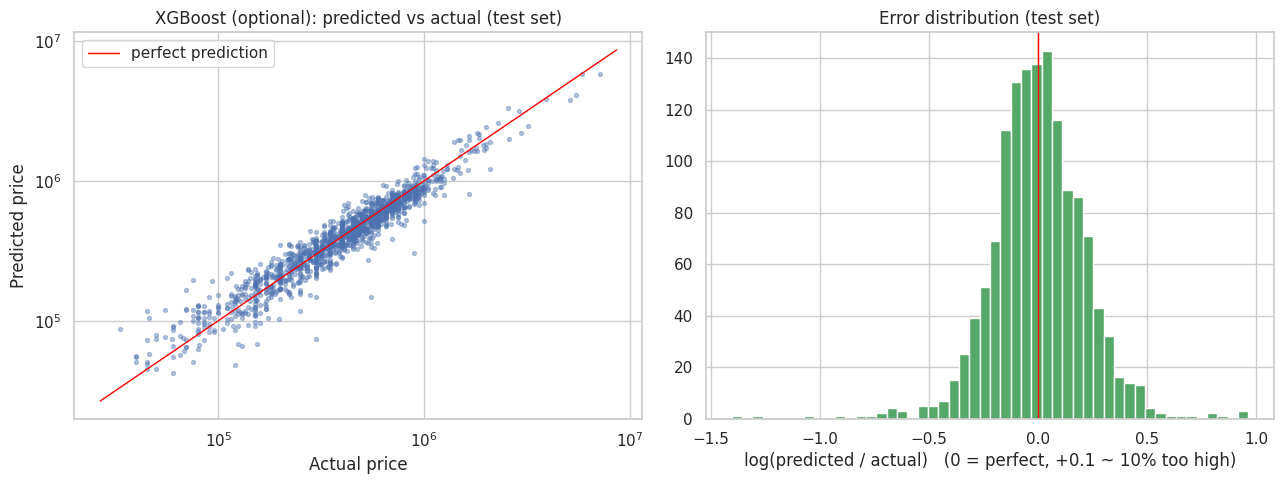

In [8]:
pred = np.clip(best_model.predict(X_test), 1, None)
err = pd.DataFrame({"name": X_test["name"], "actual": y_test, "predicted": pred})
err["pct_error"] = (err["predicted"] - err["actual"]) / err["actual"] * 100
err["abs_pct_error"] = err["pct_error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(err["actual"], err["predicted"], s=8, alpha=0.4, color="#4C72B0")
lims = [err["actual"].min() * 0.8, err["actual"].max() * 1.2]
axes[0].plot(lims, lims, color="red", lw=1, label="perfect prediction")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title(f"{best_name}: predicted vs actual (test set)")
axes[0].legend()

axes[1].hist(np.log(err["predicted"] / err["actual"]), bins=50, color="#55A868")
axes[1].axvline(0, color="red", lw=1)
axes[1].set_xlabel("log(predicted / actual)   (0 = perfect, +0.1 ~ 10% too high)")
axes[1].set_title("Error distribution (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_error_analysis.png", dpi=130, bbox_inches="tight")
plt.show()

In [9]:
bands = pd.cut(err["actual"], [0, 2e5, 4e5, 6e5, 1e6, np.inf], labels=["< 2 lakh", "2-4 lakh", "4-6 lakh", "6-10 lakh", "> 10 lakh"])
by_band = err.groupby(bands, observed=True).agg(
    cars=("actual", "size"),
    median_abs_pct_error=("abs_pct_error", "median"),
    mean_abs_error_rupees=("actual", lambda s: np.mean(np.abs(err.loc[s.index, "predicted"] - s))),
    median_signed_pct_error=("pct_error", "median"),
).round(1)
print("Accuracy by actual price band (1 lakh = 100,000; negative signed error = model predicts too LOW):")
display(by_band)

print("10 largest percentage errors on the test set:")
display(err.sort_values("abs_pct_error", ascending=False).head(10).round(1))

Accuracy by actual price band (1 lakh = 100,000; negative signed error = model predicts too LOW):


,cars,median_abs_pct_error,mean_abs_error_rupees,median_signed_pct_error
actual,,,,
< 2 lakh,276,19.0,30743.0,11.1
2-4 lakh,412,12.3,45845.8,2.5
4-6 lakh,332,11.5,68816.8,-1.9
6-10 lakh,286,9.2,90551.0,-5.4
> 10 lakh,80,13.6,284859.0,-8.0


10 largest percentage errors on the test set:


,name,actual,predicted,pct_error,abs_pct_error
1230,Maruti Wagon R VXI,33351,87387.601562,162.0,162.0
1347,Tata Indica V2 DLX TC,45000,117228.203125,160.5,160.5
665,Tata Indica V2 LSi,75000,194932.796875,159.9,159.9
992,Tata Indica Vista Terra TDI BSIII,70000,165407.203125,136.3,136.3
359,Maruti Alto LX,45957,104331.398438,127.0,127.0
821,Honda City 1.3 EXI,55000,119503.601562,117.3,117.3
7,Honda City 2017-2020 GXi,93150,191138.406250,105.2,105.2
801,Hyundai Verna 1.6 Xi ABS,114999,218938.296875,90.4,90.4
966,Tata Indica Vista TDI LS,110000,202601.203125,84.2,84.2
846,Maruti Gypsy King Soft Top,300000,73583.398438,-75.5,75.5


## 7. Feature importance

Two views, because each has a weakness:
- **Permutation importance** (main result): shuffle one original input column on the *test set* and measure how much the error rises. Works for any model and measures real predictive value. Related features share credit, so treat close values as a tie.
- **Built-in importance** (only for tree-based models): how much each feature reduced error while the trees were built. One-hot columns are summed back to their original feature.

,importance_(RMSLE_increase),std
year,0.3808,0.0075
max_power,0.2657,0.0081
name,0.0733,0.0023
fuel,0.0488,0.0022
engine,0.0351,0.0020
km_driven,0.0197,0.0022
mileage,0.0159,0.0016
owner,0.0098,0.0012
transmission,0.0068,0.0013


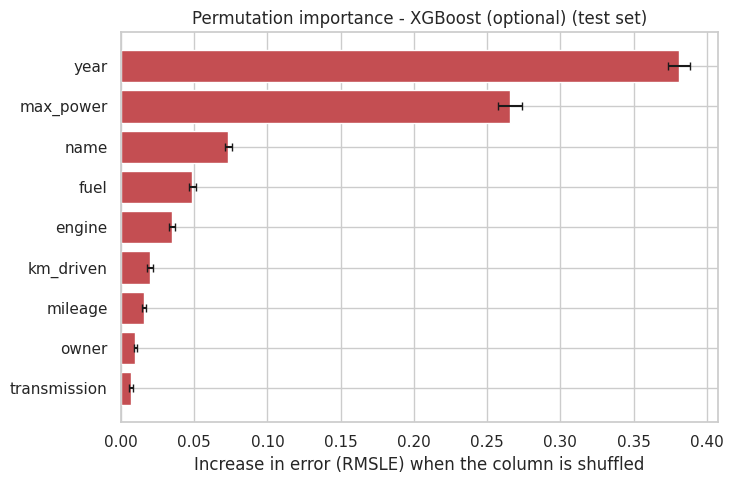

Note: `name` carries the brand; `year` carries the car age.


In [10]:
use_cols = [c for c in REQUIRED_INPUT_COLUMNS]          # the raw inputs the model needs
perm = permutation_importance(best_model, X_test[use_cols], y_test, scoring="neg_root_mean_squared_log_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
perm_df = pd.DataFrame({"importance_(RMSLE_increase)": perm.importances_mean, "std": perm.importances_std},
                       index=use_cols).sort_values("importance_(RMSLE_increase)", ascending=False)
display(perm_df.round(4))

plot_df = perm_df.sort_values("importance_(RMSLE_increase)")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(plot_df.index, plot_df["importance_(RMSLE_increase)"], xerr=plot_df["std"], color="#C44E52", capsize=3)
ax.set_xlabel("Increase in error (RMSLE) when the column is shuffled")
ax.set_title(f"Permutation importance - {best_name} (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance_permutation.png", dpi=130, bbox_inches="tight")
plt.show()
print("Note: `name` carries the brand; `year` carries the car age.")

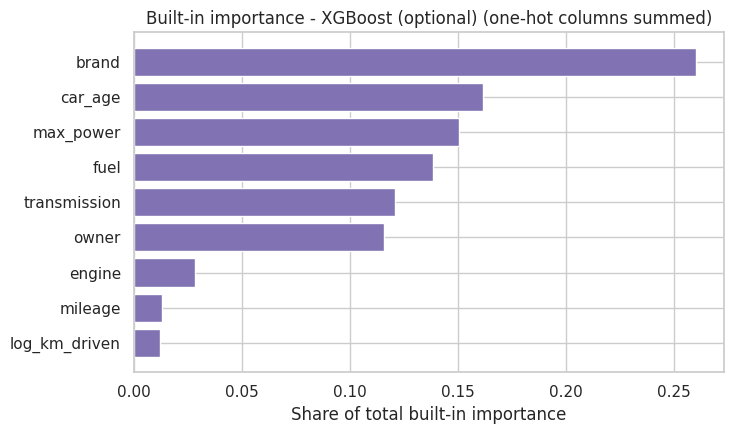

brand            0.260
car_age          0.162
max_power        0.150
fuel             0.138
transmission     0.121
owner            0.116
engine           0.028
mileage          0.013
log_km_driven    0.012


In [11]:
inner = best_model.regressor_
final_estimator = inner.named_steps["model"]
if hasattr(final_estimator, "feature_importances_"):
    names = inner.named_steps["preprocess"].get_feature_names_out()
    imp = pd.Series(final_estimator.feature_importances_, index=names)

    def base_feature(col):
        for c in CATEGORICAL_FEATURES:
            if col.startswith(c + "_"):
                return c
        return col

    grouped = imp.groupby(base_feature).sum().sort_values()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.barh(grouped.index, grouped.values, color="#8172B3")
    ax.set_xlabel("Share of total built-in importance")
    ax.set_title(f"Built-in importance - {best_name} (one-hot columns summed)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "feature_importance_builtin.png", dpi=130, bbox_inches="tight")
    plt.show()
    print(grouped.sort_values(ascending=False).round(3).to_string())
else:
    print(f"{best_name} has no built-in feature importance; the permutation importance above is the result.")

## 8. Part 4: Save the best model (Joblib **and** Pickle)

We save the **entire pipeline** (feature engineering + imputing + scaling + encoding + model + log-price conversion). So the saved file accepts a raw car description and returns a price in rupees, and the Streamlit app needs no extra preprocessing code.

We also store a small JSON file with the metrics, settings, library versions and input ranges, so anyone can see what the model is, how it was made, and which library versions it needs.

In [12]:
# Typical size of the model's mistakes, from OUT-OF-FOLD predictions on the training set (test set not used)
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, n_jobs=1)
ratio = y_train.to_numpy() / np.clip(oof, 1, None)             # actual / predicted
q10, q90 = np.quantile(ratio, [0.10, 0.90])
inside = ((y_test / pred >= q10) & (y_test / pred <= q90)).mean()
print(f"Indicative range = predicted x [{q10:.2f}, {q90:.2f}]  (middle 80% of out-of-fold errors on training data)")
print(f"Check on the untouched test set: {inside:.1%} of test cars fall inside that range")

Indicative range = predicted x [0.78, 1.27]  (middle 80% of out-of-fold errors on training data)
Check on the untouched test set: 79.9% of test cars fall inside that range


In [13]:
brand_counts = pd.Series(
    X_train["name"].str.split().str[0].replace({"Land": "Land Rover"})).value_counts()
metadata = {
    "project": "Used-car price prediction (Devixo Solutions AI/ML Internship, Task 03)",
    "created": date.today().isoformat(),
    "selected_model": best_name,
    "best_hyperparameters": best_params[best_name],
    "selection_rule": "lowest 5-fold cross-validated RMSLE on the training set after RandomizedSearchCV",
    "cv_metrics_train": {k: float(v) for k, v in tuned_table.loc[best_name].items()},
    "test_metrics": {k: float(v) for k, v in test_table.loc[best_name].items()},
    "indicative_range_ratio": {"low": float(q10), "high": float(q90), "test_coverage": float(inside)},
    "features": {"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES,
                 "required_input_columns": REQUIRED_INPUT_COLUMNS},
    "training_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "currency_note": "Prices are in the dataset's currency (assumed Indian rupees; CarDekho listings). Newest car year is 2020.",
    "input_choices": {
        "brand": [b for b, n in brand_counts.items() if n >= 10],
        "fuel": sorted(X_train["fuel"].dropna().unique().tolist()),
        "transmission": sorted(X_train["transmission"].dropna().unique().tolist()),
        "owner": X_train["owner"].value_counts().index.tolist(),
    },
    "input_ranges": {
        "year": [int(X_train["year"].min()), int(X_train["year"].max())],
        "km_driven_p99": float(X_train["km_driven"].quantile(0.99)),
        "mileage_p01_p99": [float(v) for v in
            X_train["mileage"].str.extract(r"^\s*(\d+(?:\.\d+)?)")[0].astype(float).quantile([0.01, 0.99])],
        "engine_cc_p01_p99": [float(v) for v in
            X_train["engine"].str.extract(r"^\s*(\d+(?:\.\d+)?)")[0].astype(float).quantile([0.01, 0.99])],
        "max_power_bhp_p01_p99": [float(v) for v in
            X_train["max_power"].str.extract(r"^\s*(\d+(?:\.\d+)?)")[0].astype(float).quantile([0.01, 0.99])],
    },
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__,
                         **({"xgboost": __import__("xgboost").__version__} if HAVE_XGB else {})},
}

joblib_path = MODEL_DIR / "best_model.joblib"
pickle_path = MODEL_DIR / "best_model.pkl"
joblib.dump(best_model, joblib_path, compress=3)
with open(pickle_path, "wb") as f:
    pickle.dump(best_model, f)
with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

for p in [joblib_path, pickle_path, MODEL_DIR / "model_metadata.json"]:
    print(f"{p.name:22s} {p.stat().st_size / 1e6:8.2f} MB")

best_model.joblib          0.40 MB
best_model.pkl             1.40 MB
model_metadata.json        0.00 MB


### Verify the saved files (never trust a save you have not reloaded)
Three checks: (1) both files reload and agree with the in-memory model, (2) a **brand-new Python process** can load them and predict, (3) the input can contain missing values and brands the model has never seen.

In [14]:
loaded_joblib = joblib.load(joblib_path)
with open(pickle_path, "rb") as f:
    loaded_pickle = pickle.load(f)

p_mem = best_model.predict(X_test)
print("Joblib  reload identical to in-memory model:", np.allclose(p_mem, loaded_joblib.predict(X_test)))
print("Pickle  reload identical to in-memory model:", np.allclose(p_mem, loaded_pickle.predict(X_test)))

# (2) fresh interpreter, as if on another computer
snippet = (
    "import joblib, pickle, pandas as pd;"
    "t = pd.read_csv('data/processed/test.csv').head(5);"
    "a = joblib.load('models/best_model.joblib').predict(t);"
    "b = pickle.load(open('models/best_model.pkl','rb')).predict(t);"
    "print([round(float(x)) for x in a]); print([round(float(x)) for x in b])"
)
out = subprocess.run([sys.executable, "-W", "ignore", "-c", snippet], cwd=ROOT, capture_output=True, text=True)
print("Fresh-process check -> return code:", out.returncode)
print(out.stdout.strip() or out.stderr.strip()[-500:])
print("First 5 actual prices:", y_test.head(5).tolist())

# (3) awkward input: missing numbers + a brand never seen in training
odd = pd.DataFrame([{"name": "Tesla Model S", "year": 2019, "km_driven": 30000, "fuel": "Petrol",
                     "transmission": "Automatic", "owner": "First Owner",
                     "mileage": np.nan, "engine": np.nan, "max_power": np.nan}])
print("Prediction with missing specs and an unseen brand:", round(float(loaded_joblib.predict(odd)[0])))

Joblib  reload identical to in-memory model: True


Pickle  reload identical to in-memory model: True


Fresh-process check -> return code: 0
[605438, 1076630, 772805, 128515, 712693]
[605438, 1076630, 772805, 128515, 712693]
First 5 actual prices: [550000, 1225000, 850000, 80000, 825000]
Prediction with missing specs and an unseen brand: 765395


## 9. Summary of results (all numbers copied from the outputs above)

**Model comparison, 5-fold cross-validation on the training set (RMSLE, lower is better)**

| Model | Default | Tuned | Tuned CV R2 | Tuned CV MAE |
|---|---|---|---|---|
| XGBoost (optional) | 0.2284 | **0.2178** | 0.8825 | 77,570 |
| Gradient Boosting | 0.2342 | 0.2209 | 0.8843 | 78,691 |
| Random Forest | 0.2300 | 0.2227 | 0.8769 | 80,046 |
| SVR | 0.2295 | 0.2299 | 0.8338 | 82,124 |
| Decision Tree | 0.2990 | 0.2623 | 0.8375 | 94,892 |
| *Ridge regression (reference)* | 0.2626 | - | - | - |
| *Always predict the median price* | 0.7678 | - | - | - |

**Selected model: XGBoost** (the rule "lowest tuned CV RMSLE" picked it). Settings: 600 trees, learning rate 0.03, max depth 5, subsample 0.85, colsample_bytree 0.6, min_child_weight 3.

**Test set (1,386 cars, used once)**

| Model | R2 | MAE (rupees) | RMSE | RMSLE | Median % error |
|---|---|---|---|---|---|
| **XGBoost (selected)** | 0.9275 | 71,361 | 126,069 | 0.2153 | 12.3% |
| Gradient Boosting | 0.9401 | 69,992 | 114,649 | 0.2164 | 12.6% |
| Random Forest | 0.9225 | 72,025 | 130,394 | 0.2250 | 12.6% |
| SVR | 0.8544 | 76,556 | 178,726 | 0.2279 | 12.7% |
| Decision Tree | 0.8987 | 84,069 | 149,089 | 0.2547 | 13.9% |
| Always predict the median | -0.0460 | 259,547 | 478,963 | 0.7488 | 42.9% |

**What this does and does not show**

1. **XGBoost vs Gradient Boosting is a tie, not a victory.** The CV gap (0.0031) is smaller than the fold-to-fold noise (0.0113). On the test set Gradient Boosting is slightly better on R2 and MAE, and XGBoost on RMSLE. We keep XGBoost because the rule was fixed *before* looking at the test set. Switching afterwards would be choosing a model with the test set.
2. **Why test R2 (0.93) is higher than cross-validation R2 (0.88):** R2 is dominated by a few very expensive cars. The test set happens to contain only 6 cars above 30 lakh, while the training set has 43 (a fair share would be about 11). So the test set's prices are less spread out, which flatters R2. RMSLE barely changes (0.2178 in CV vs 0.2153 on test), so **RMSLE and the median percentage error are the more trustworthy summaries.**
3. **Tuning helped most for the trees and boosting models** (improvement 0.007 to 0.037) and **did not help SVR** (-0.0004). SVR's best setting was `C=1`, the smallest value we offered, so our search range may have been too narrow for it.
4. **A simple Ridge regression (0.2626) is clearly worse than the tree-based models (0.218 to 0.223).** The extra complexity is justified.

**Error analysis (test set)**

| Actual price band | Cars | Median % error | Median signed error |
|---|---|---|---|
| under 2 lakh | 276 | 19.0% | +11.1% (too high) |
| 2-4 lakh | 412 | 12.3% | +2.5% |
| 4-6 lakh | 332 | 11.5% | -1.9% |
| 6-10 lakh | 286 | 9.2% | -5.4% |
| over 10 lakh | 80 | 13.6% | -8.0% (too low) |

The model is least accurate for **very cheap, old cars** (it tends to over-price them) and tends to **under-price expensive cars**. The nine largest over-estimates are all cheap old cars (for example a Maruti Wagon R that sold for 33,351 was predicted at about 87,000). The single largest under-estimate is a Maruti Gypsy King (actual 300,000, predicted about 73,600).

**Feature importance**

- *Permutation importance on the test set* (rise in RMSLE when the column is shuffled): `year` (car age) 0.381, `max_power` 0.266, `name` (brand) 0.073, `fuel` 0.049, `engine` 0.035, `km_driven` 0.020, `mileage` 0.016, `owner` 0.010, `transmission` 0.007.
- *XGBoost built-in importance* gives a different order (brand 0.26, car_age 0.16, max_power 0.15, fuel 0.14, transmission 0.12, owner 0.12). The two differ because the built-in score is spread across one-hot columns and favours features with many splits. **We trust the permutation result**, which measures real predictive value on unseen data.
- Importance shows what the model *uses*, not what *causes* a price.

**Saved files:** `models/best_model.joblib` (0.40 MB) and `models/best_model.pkl` (1.40 MB), plus `models/model_metadata.json`. Both reload to predictions identical to the in-memory model, both work in a fresh Python process, and the model handles missing specs and an unseen brand.

**Indicative price range used by the app:** predicted price x [0.78, 1.27]. This is the middle 80% of out-of-fold errors on training data; on the untouched test set 79.9% of cars fell inside such a range.